In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict


/tmp/ipykernel_780/2591094532.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  box = sns.boxplot(x='Model', y='Accuracy', data=df, linewidth=0.6,


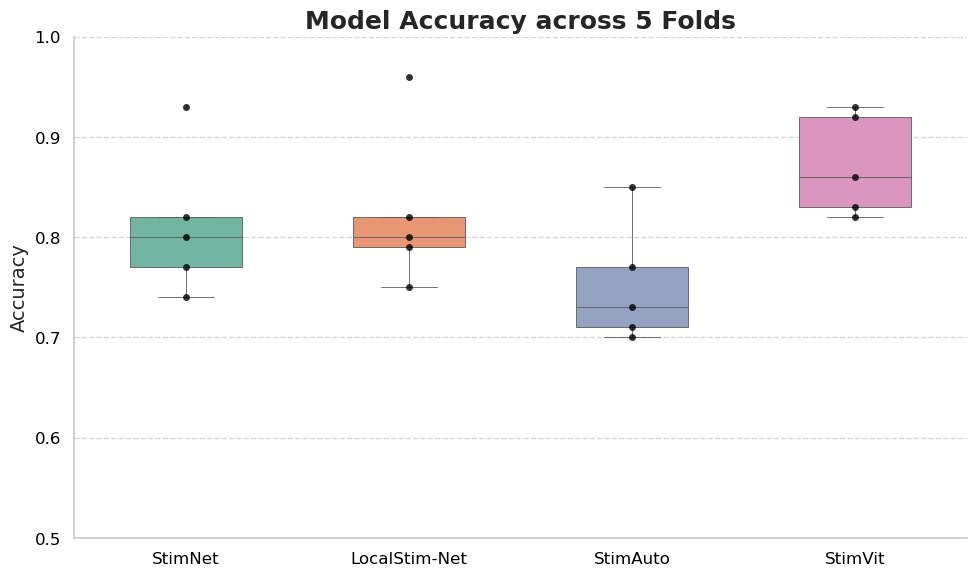

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set a modern Seaborn theme
sns.set(style="whitegrid", palette="pastel", font_scale=1.2)

# Example accuracies for each model across 5 folds
accuracies = {
    'StimNet': [0.93, 0.77, 0.80, 0.82, 0.74] ,
    'LocalStim-Net': [0.79, 0.80, 0.96, 0.75, 0.82],
    'StimAuto': [0.71, 0.77, 0.85, 0.73, 0.70],
    'StimVit': [0.93, 0.83, 0.86, 0.82, 0.92],
}

# Convert to long-form DataFrame
data = []
for model, scores in accuracies.items():
    for score in scores:
        data.append({'Model': model, 'Accuracy': score})
df = pd.DataFrame(data)

# Create the plot
plt.figure(figsize=(10, 6))
box = sns.boxplot(x='Model', y='Accuracy', data=df, linewidth=0.6, 
                  palette='Set2', width=0.5, fliersize=0.2)
sns.stripplot(x='Model', y='Accuracy', data=df, color='black', size=5, alpha=0.8, jitter=0.0)

# Styling
plt.title('Model Accuracy across 5 Folds', fontsize=18, fontweight='bold')
plt.ylabel('Accuracy', fontsize=14)
plt.xlabel('')
plt.ylim(0.5, 1.0)
plt.xticks(fontsize=12,color='black')
plt.yticks(fontsize=12,color='black')
plt.grid(True, axis='y', linestyle='--', alpha=0.78)
sns.despine()

# Show the plot
plt.tight_layout()
plt.show()


/tmp/ipykernel_67449/3896720729.py:52: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[c], edgecolor="black") for c in class_counts.keys()]


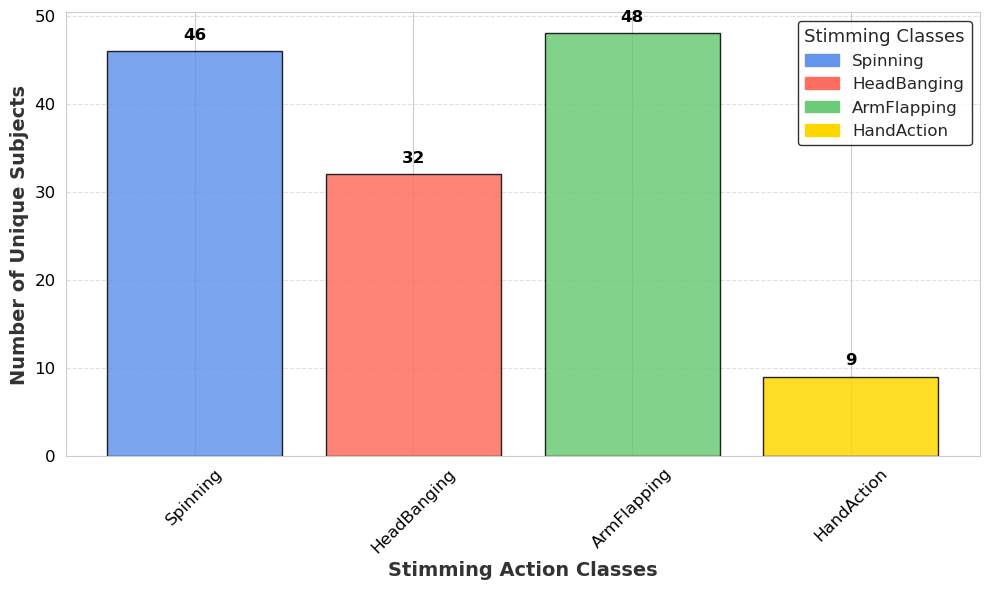

In [40]:
# Define the file path
file_path = r"/home/nyam/Ms_Thesis/Autism/ASBD-Autism-Stimming-Behavior-Datase-New.xlsx"

# Load the Excel file into a DataFrame
df = pd.read_excel(file_path)

# Filter the data where "Available" column is "Y"
df_filtered = df[df["Available"] == "Y"]

# Dictionary to store unique subjects per class
class_subjects = defaultdict(set)

# Extract category and subject ID from the "Video" column
for video_title in df_filtered["Video"]:
    parts = video_title.split('_')  # Split the video title by "_"
    if len(parts) >= 3:
        class_label = parts[1]  # Extract class name (e.g., ArmFlapping)
        subject_id = f"{parts[1]}_{parts[2]}"  # Extract unique subject ID (e.g., ArmFlapping_38)
        class_subjects[class_label].add(subject_id)  # Store unique subject ID in respective class

# Count the number of unique subjects per class
class_counts = {class_label: len(subjects) for class_label, subjects in class_subjects.items()}

# Define a soothing color palette for the four classes
class_colors = {
    "Spinning": "#6495ED",      # Cornflower Blue
    "HeadBanging": "#FF6F61",   # Soft Red
    "ArmFlapping": "#6BCB77",   # Pastel Green
    "HandAction": "#FFD700"     # Gold
}

# Filter to keep only relevant classes
class_counts = {k: class_counts[k] for k in class_colors.keys() if k in class_counts}

# Create the bar plot with enhanced aesthetics
plt.figure(figsize=(10, 6))
bars = plt.bar(class_counts.keys(), class_counts.values(), 
               color=[class_colors[c] for c in class_counts.keys()], 
               edgecolor="black", alpha=0.85)

# Add value labels on top of bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, str(bar.get_height()),
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

# Customize the plot aesthetics
plt.xlabel("Stimming Action Classes", fontsize=14, fontweight='bold', color="#333333")
plt.ylabel("Number of Unique Subjects", fontsize=14, fontweight='bold', color="#333333")
#plt.title("Number of Unique Subjects Across Stimming Action Classes", fontsize=16, fontweight='bold', color="#444444")

# Create a properly formatted legend
handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[c], edgecolor="black") for c in class_counts.keys()]
plt.legend(handles, class_counts.keys(), title="Stimming Classes", title_fontsize=13, fontsize=12, 
           frameon=True, edgecolor="black", loc="upper right")

# Adjust x-axis labels for better readability
plt.xticks(rotation=45, fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')

# Add subtle grid lines
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Optimize layout
plt.tight_layout()

# Show the final plot
plt.show()


/tmp/ipykernel_371689/1616273031.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rating_dist = subject_ratings.groupby(["Class", "Rating Bin"]).size().unstack().fillna(0)


<Figure size 1000x600 with 0 Axes>

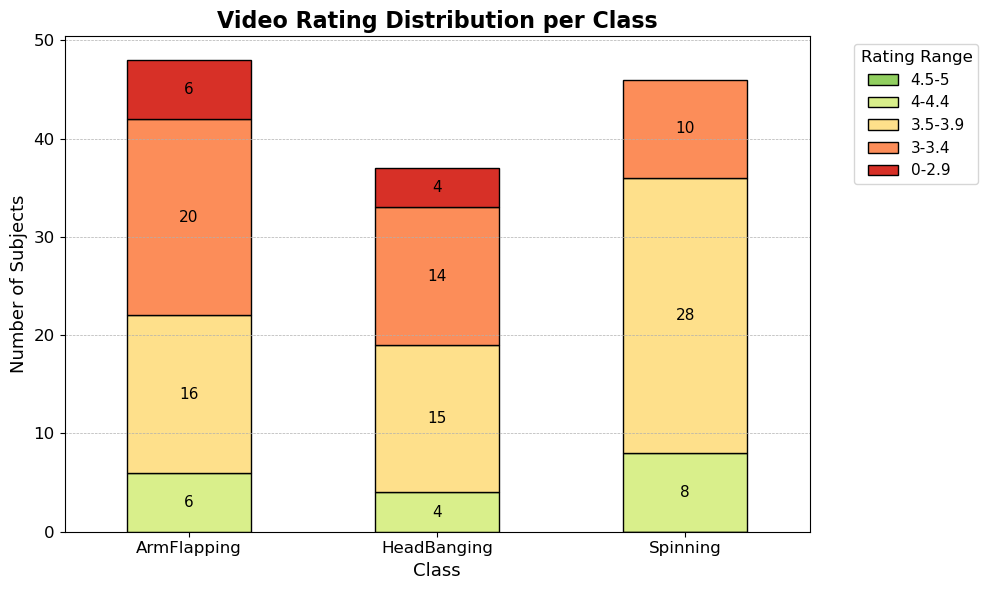

In [7]:
# Load the Excel file
file_path = r"/home/nyam/Ms_Thesis/Autism/ASBD-Autism-Stimming-Behavior-Datase-New.xlsx"
sheet_name = "Sheet2"

# Read the sheet
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Drop unused columns (like unnamed tail columns)
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Filter relevant classes
df = df[df["Class"].isin(["ArmFlapping", "HeadBanging", "Spinning"])]

# Extract subject ID from video filename
df["Subject"] = df["Video"].apply(lambda x: "_".join(x.split("_")[2:4]) if len(x.split("_")) > 2 else x.split("_")[-1])

# Compute average rating per subject
subject_ratings = df.groupby(["Class", "Subject"])["Rating"].mean().reset_index()

# Create rating bins
subject_ratings["Rating Bin"] = pd.cut(
    subject_ratings["Rating"],
    bins=[0, 2.9, 3.4, 3.9, 4.4, 5],
    labels=["0-2.9", "3-3.4", "3.5-3.9", "4-4.4", "4.5-5"]
)

# Group and count
rating_dist = subject_ratings.groupby(["Class", "Rating Bin"]).size().unstack().fillna(0)

# Reorder rating bins from high (bottom) to low (top)
rating_bin_order = ["4.5-5", "4-4.4", "3.5-3.9", "3-3.4", "0-2.9"]
rating_dist = rating_dist[rating_bin_order[::-1]]  # reversed for bottom-up stack

# Stack colors: from red to green (low to high)
stack_colors = ["#d73027", "#fc8d59", "#fee08b", "#d9ef8b", "#91cf60"]  # low to high

# Plot
plt.figure(figsize=(10, 6))
ax = rating_dist[rating_bin_order].plot(
    kind="bar", 
    stacked=True, 
    figsize=(10, 6), 
    color=stack_colors[::-1],  # match bottom-up
    edgecolor='black'
)

plt.title("Video Rating Distribution per Class", fontsize=16, fontweight='bold')
plt.xlabel("Class", fontsize=13)
plt.ylabel("Number of Subjects", fontsize=13)
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', linewidth=0.5)

# Add count labels
for i, class_name in enumerate(rating_dist.index):
    y_offset = 0
    for rating_bin in rating_bin_order:
        val = rating_dist.loc[class_name, rating_bin]
        if val > 0:
            plt.text(i, y_offset + val / 2, int(val), ha='center', va='center', fontsize=11)
            y_offset += val

plt.legend(title="Rating Range", title_fontsize=12, fontsize=11, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


/tmp/ipykernel_67449/262155615.py:43: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[label], edgecolor="black") for label in class_labels]


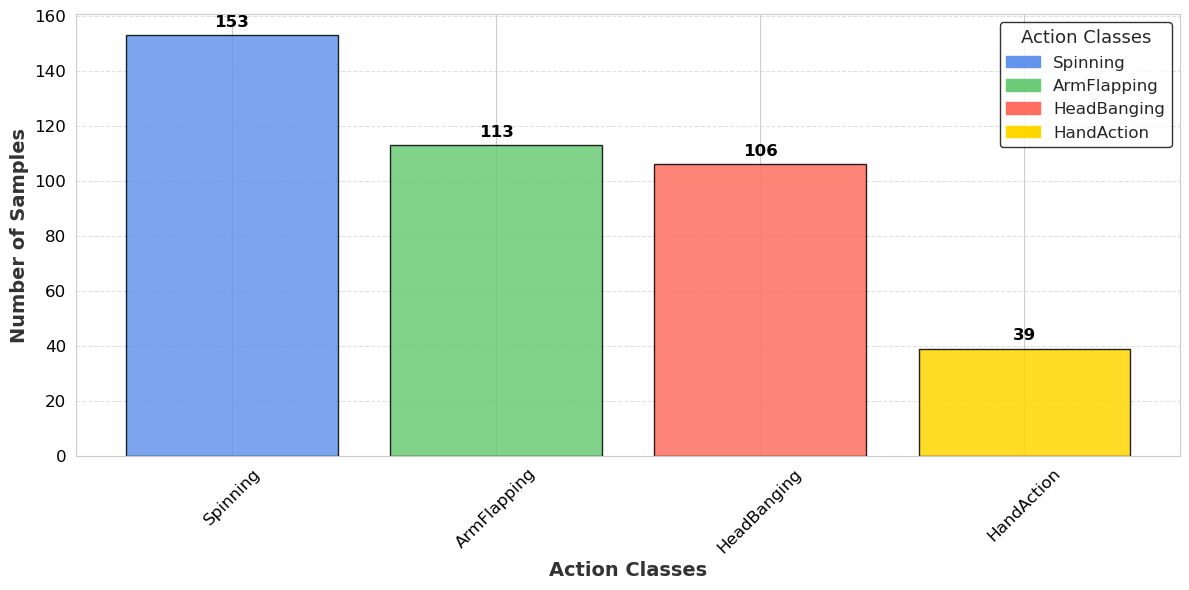

In [58]:
# Define the file path
file_path = r"/home/nyam/Ms_Thesis/Autism/project_v2/Dataset_processing/dataset_info_before.txt"

# Load the text file into a DataFrame
df = pd.read_csv(file_path, delimiter="\t", header=None, names=["NO", "ID", "Class"])

# Count occurrences of each class
class_counts = Counter(df["ID"])

# Sort classes by count for better visualization
sorted_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
class_labels, class_values = zip(*sorted_classes)

# Define a soothing color palette for the four classes
class_colors = {
    "Spinning": "#6495ED",      # Cornflower Blue
    "HeadBanging": "#FF6F61",   # Soft Red
    "ArmFlapping": "#6BCB77",   # Pastel Green
    "HandAction": "#FFD700"     # Gold
}

# Ensure the colors are assigned correctly based on the actual labels in the dataset
bar_colors = [class_colors[label] for label in class_labels]

# Create the bar plot with enhanced aesthetics
plt.figure(figsize=(12, 6))
bars = plt.bar(class_labels, class_values, color=bar_colors, edgecolor="black", alpha=0.85)

# Add value labels on top of bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, str(bar.get_height()),
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

# Customize the plot aesthetics
plt.xlabel("Action Classes", fontsize=14, fontweight='bold', color="#333333")
plt.ylabel("Number of Samples", fontsize=14, fontweight='bold', color="#333333")

# Add a properly ordered legend
handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[label], edgecolor="black") for label in class_labels]
plt.legend(handles, class_labels, title="Action Classes", title_fontsize=13, fontsize=12, frameon=True, edgecolor="black", loc="upper right")

# Rotate x-axis labels for readability
plt.xticks(rotation=45, fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')

# Add subtle grid lines
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Optimize layout
plt.tight_layout()

# Show the final plot
plt.show()


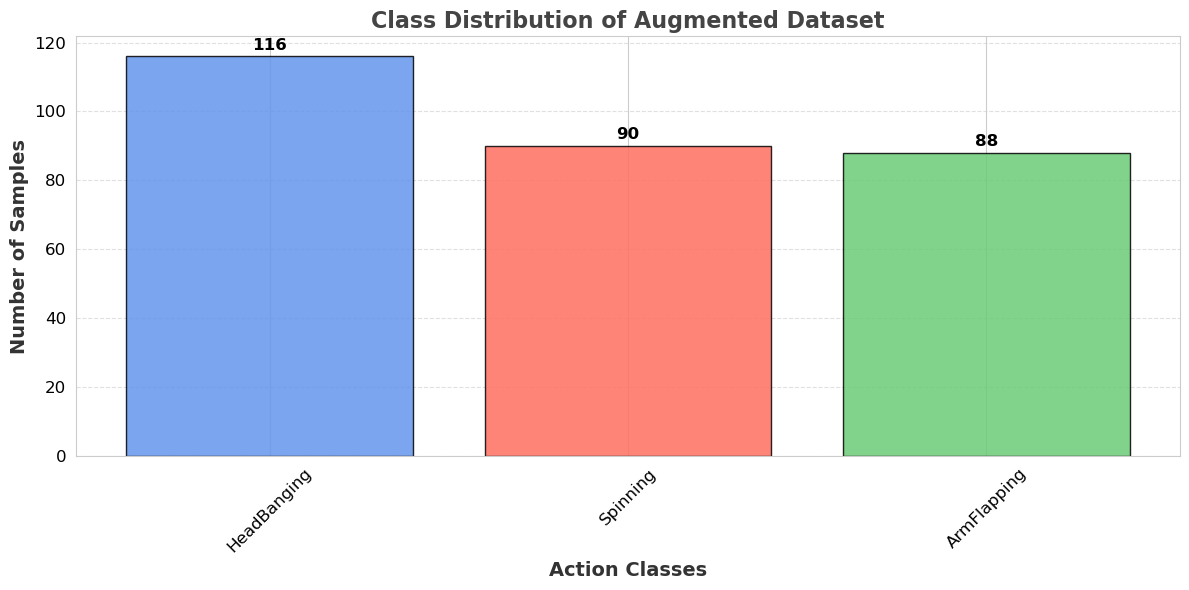

In [4]:
# Define the file path
file_path = r"/home/nyam/Ms_Thesis/Autism/Project_v3/DataProcessing/dataset_info.txt"

# Load the text file into a DataFrame
df = pd.read_csv(file_path, delimiter="\t", header=None, names=["SNO", "ID", "Class"])

# Count occurrences of each class
class_counts = Counter(df[df["ID"] != "HandAction"]["ID"])

# Sort classes by count for better visualization
sorted_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
class_labels, class_values = zip(*sorted_classes)

# Set a clean seaborn style
sns.set_style("whitegrid")

# Define a smooth and professional color palette
colors = ["#6495ED", "#FF6F61", "#6BCB77", "#FFD700", "#BA68C8"][:len(class_labels)] 

# Create a bar plot with improved aesthetics
plt.figure(figsize=(12, 6))
bars = plt.bar(class_labels, class_values, color=colors, edgecolor="black", alpha=0.85)

# Add value labels on top of bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, str(bar.get_height()),
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

# Customize the plot aesthetics
plt.xlabel("Action Classes", fontsize=14, fontweight='bold', color="#333333")
plt.ylabel("Number of Samples", fontsize=14, fontweight='bold', color="#333333")
plt.title("Class Distribution of Augmented Dataset", fontsize=16, fontweight='bold', color="#444444")

# Adjust x-axis labels for better readability
plt.xticks(rotation=45, fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')

# Add subtle grid lines
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Optimize layout for a clean look
plt.tight_layout()

# Show the final plot
plt.show()


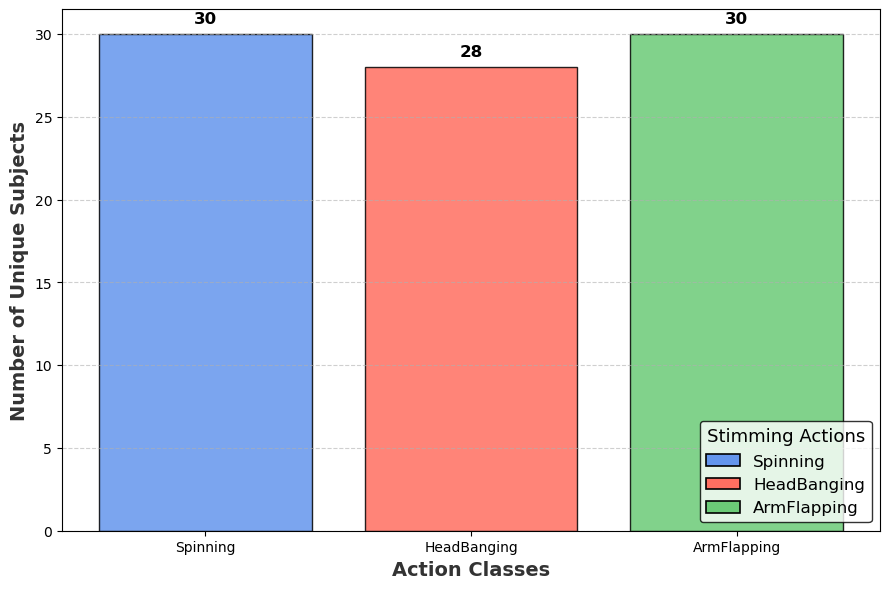

In [2]:
# Define soft color palette
class_colors = {
    "Spinning": "#6495ED",      # Cornflower Blue
    "HeadBanging": "#FF6F61",   # Soft Red
    "ArmFlapping": "#6BCB77",   # Pastel Green
}

# Define the dataset file path
file_path = r"/home/nyam/Ms_Thesis/Autism/Project_v3/DataProcessing/dataset_info.txt" # Update this path accordingly

# Load dataset info from file
dataset_info = []
with open(file_path, 'r') as file:
    for line in file:
        dataset_info.append(line.strip().split('\t'))

# Dictionary to store unique subjects per class
class_subject_count = defaultdict(set)

# Process dataset to count unique subjects per class
for info in dataset_info:
    class_label = info[1]  # Extract class label
    if class_label == "HandAction":
        continue
    filename = info[2]  # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
    
    # Store unique subjects in the respective class set
    class_subject_count[class_label].add(subject_id)

# Count the number of unique subjects per class
class_counts = {class_label: len(subjects) for class_label, subjects in class_subject_count.items()}

# Plotting the bar chart for number of subjects per class
plt.figure(figsize=(9, 6))
bars = plt.bar(class_counts.keys(), class_counts.values(), color=[class_colors[c] for c in class_counts.keys()], edgecolor="black", alpha=0.85)

# Add value labels on top of bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, str(bar.get_height()),
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

# Add labels and title with a modern font style
plt.xlabel("Action Classes", fontsize=14, fontweight='bold', color="#333333")
plt.ylabel("Number of Unique Subjects", fontsize=14, fontweight='bold', color="#333333")
#plt.title("Distribution of Subjects Across Stimming Action Classes", fontsize=16, fontweight='bold', color="#444444")

# Create and add a legend with a soft border
handles = [plt.Rectangle((0, 0), 1, 1, color=color, ec="black", lw=1.2) for color in class_colors.values()]
plt.legend(handles, class_colors.keys(), title="Stimming Actions", title_fontsize=13, fontsize=12, frameon=True, edgecolor="black", loc="lower right")

# Make the grid more subtle
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Show the plot
plt.tight_layout()
plt.show()


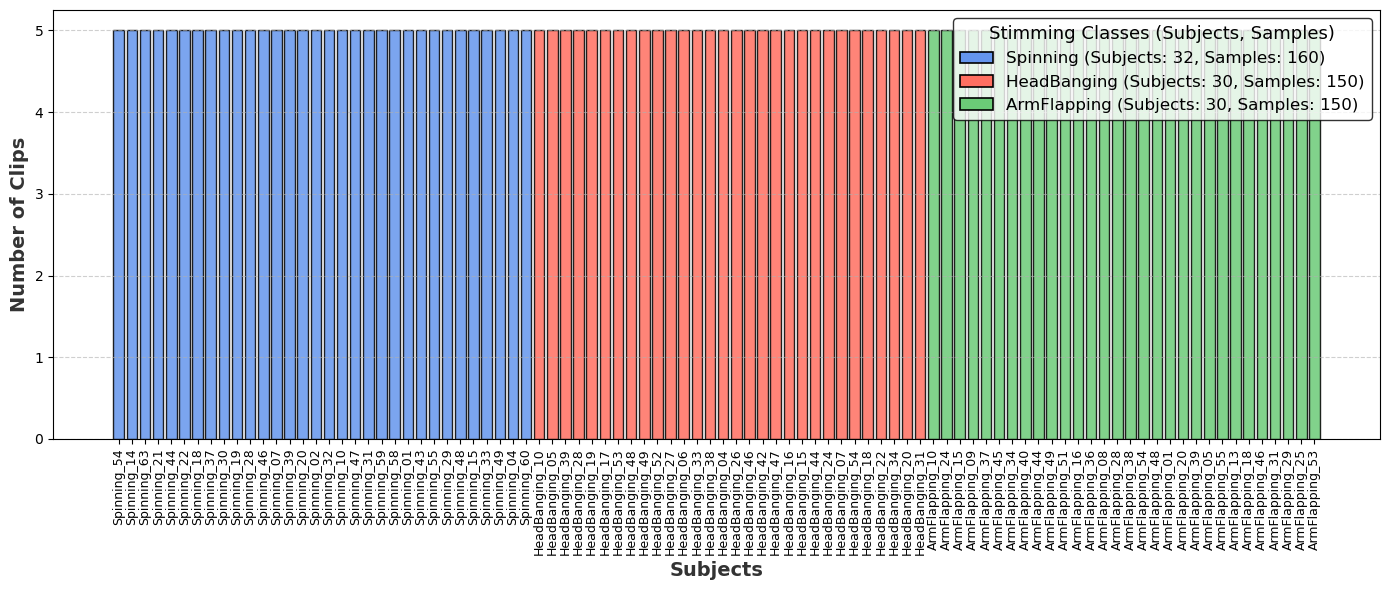

In [7]:
import matplotlib.pyplot as plt
from collections import defaultdict

# Define a soft color palette
class_colors = {
    "Spinning": "#6495ED",      # Cornflower Blue
    "HeadBanging": "#FF6F61",   # Soft Red
    "ArmFlapping": "#6BCB77",   # Pastel Green
}

# Define the dataset file path
file_path = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Code_Base/DataProcessing/v2/dataset_info_clean_aug.txt"

# Load dataset info from file
dataset_info = []
with open(file_path, 'r') as file:
    for line in file:
        dataset_info.append(line.strip().split('\t'))

# Dictionaries to store subject data
subject_clip_count = defaultdict(int)  # Stores clip count per subject
subject_class_mapping = {}  # Stores class labels per subject
class_sample_count = defaultdict(int)  # Stores total number of clips per class
class_subject_count = defaultdict(set)  # Stores unique subject IDs per class

# Process dataset to extract subject IDs, count clips, and assign class labels
for info in dataset_info:
    class_label = info[1]  # Extract class label
    if class_label == "HandAction":
        continue
    filename = info[2]  # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
    
    # Update counts and mappings
    subject_clip_count[subject_id] += 1
    subject_class_mapping[subject_id] = class_label  # Assign class label
    class_sample_count[class_label] += 1  # Count total number of clips per class
    class_subject_count[class_label].add(subject_id)  # Track unique subjects per class

# Group subjects by class
class_subjects = defaultdict(list)
for subject, count in subject_clip_count.items():
    class_label = subject_class_mapping[subject]
    class_subjects[class_label].append((subject, count))

# Sort subjects within each class by clip count (descending)
sorted_subjects = []
sorted_clip_counts = []
sorted_colors = []

for class_label, subjects in class_subjects.items():
    subjects.sort(key=lambda x: x[1], reverse=True)  # Sort by clip count
    for subject, count in subjects:
        sorted_subjects.append(subject)
        sorted_clip_counts.append(count)
        sorted_colors.append(class_colors[class_label])

# Create the bar plot
plt.figure(figsize=(14, 6))
bars = plt.bar(sorted_subjects, sorted_clip_counts, color=sorted_colors, edgecolor="black", alpha=0.85)

# Add a y-axis for readability
plt.ylabel("Number of Clips", fontsize=14, fontweight='bold', color="#333333")

# Create a styled legend with unique subjects and total samples per class
legend_labels = [f"{cls} (Subjects: {len(class_subject_count[cls])}, Samples: {class_sample_count[cls]})" 
                 for cls in class_colors.keys()]
handles = [plt.Rectangle((0, 0), 1, 1, color=class_colors[cls], ec="black", lw=1.2) for cls in class_colors.keys()]
plt.legend(handles, legend_labels, title="Stimming Classes (Subjects, Samples)", title_fontsize=13, fontsize=12, 
           frameon=True, edgecolor="black", loc="upper right")

# Adjust x-axis labels for readability
plt.xticks(rotation=90, fontsize=9)
plt.xlabel("Subjects", fontsize=14, fontweight='bold', color="#333333")
#plt.title("Number of Clips per Subject (Grouped by Stimming Action Class)", fontsize=16, fontweight='bold', color="#444444")

# Enhance readability with subtle grid lines
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Optimize layout
plt.tight_layout()

# Show the final plot
plt.show()
